#Surface by surface simulation

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from utilities import make_grid, angular_spectrum, pupil, plot_field
from ilumination import source_field, source_spectrum, mirror_pupil

###Source

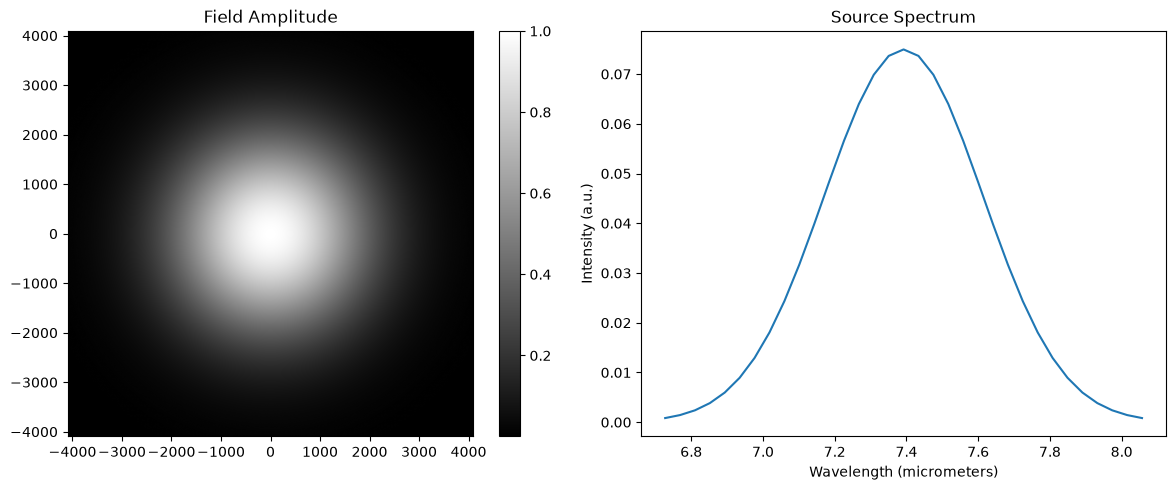

In [6]:
central_lam = 0.850 # central wavelength in micrometers
fwhm = 0.06  # full width at half maximum in micrometers
n = np.array([4096, 4096])
dx, dy = 2, 2
w0 = 2e3

X, Y = make_grid(n, dx, dy)
U_source = source_field(X, Y, central_lam, w0)
S_source = source_spectrum(central_lam, fwhm, n_k=33)

#Plot field amplitude and phase
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(np.abs(U_source), extent=[X.min(), X.max(), Y.min(), Y.max()], cmap='gray')
plt.title('Field Amplitude')
plt.colorbar()

plt.subplot(1, 2, 2)
plt.plot(S_source[0], S_source[1])
plt.title('Source Spectrum')
plt.xlabel('Wavelength (micrometers)')
plt.ylabel('Intensity (a.u.)')

plt.tight_layout()
plt.show()

###Just before mirror

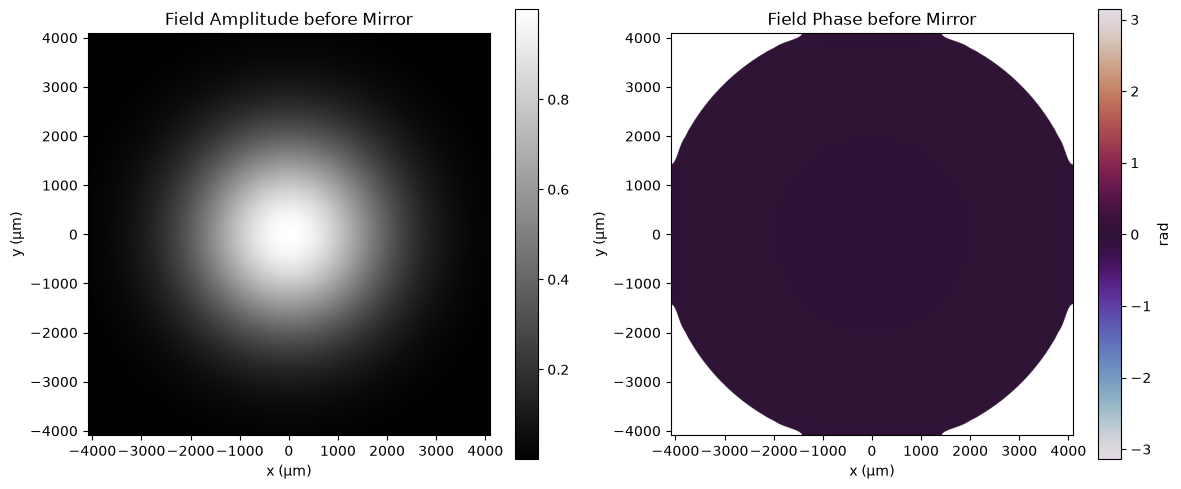

In [7]:
z_M1 = 50e3  # distance to mirror in micrometers

U_M1_ = angular_spectrum(U_source, dx=dx, dy=dy, z=z_M1, lam=central_lam)

plot_field(U_M1_, X, Y, 'before Mirror', z=z_M1, lam=central_lam)

###Just after mirror

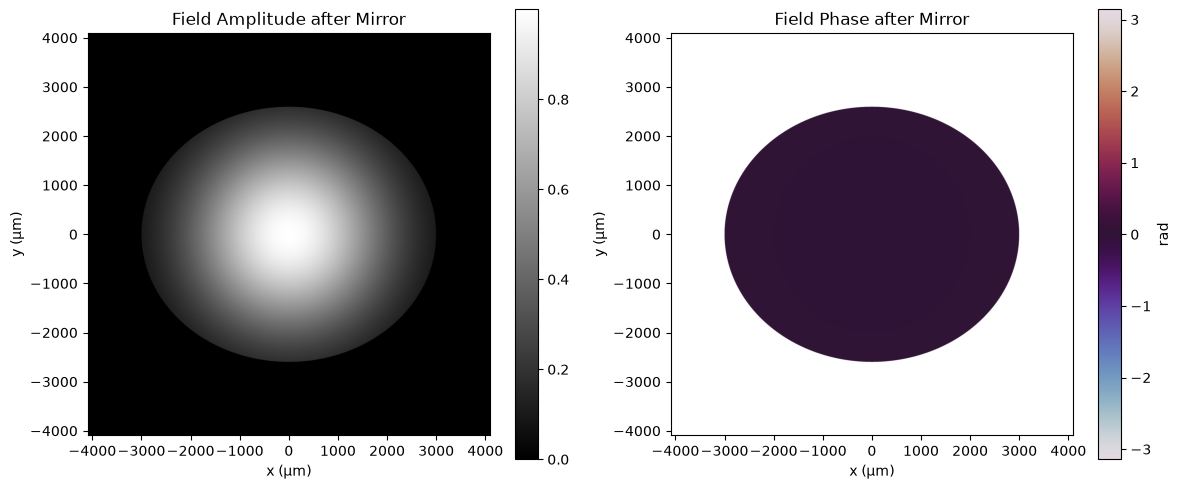

In [8]:
M1_r = 3e3 # Mirror 1 radius in micrometers
M1_theta = 30
P_M1 = mirror_pupil(X, Y, M1_r, M1_theta)

U_M1 = U_M1_ * P_M1

plot_field(U_M1, X, Y, 'after Mirror', z=z_M1, lam=central_lam)

###Just before sample

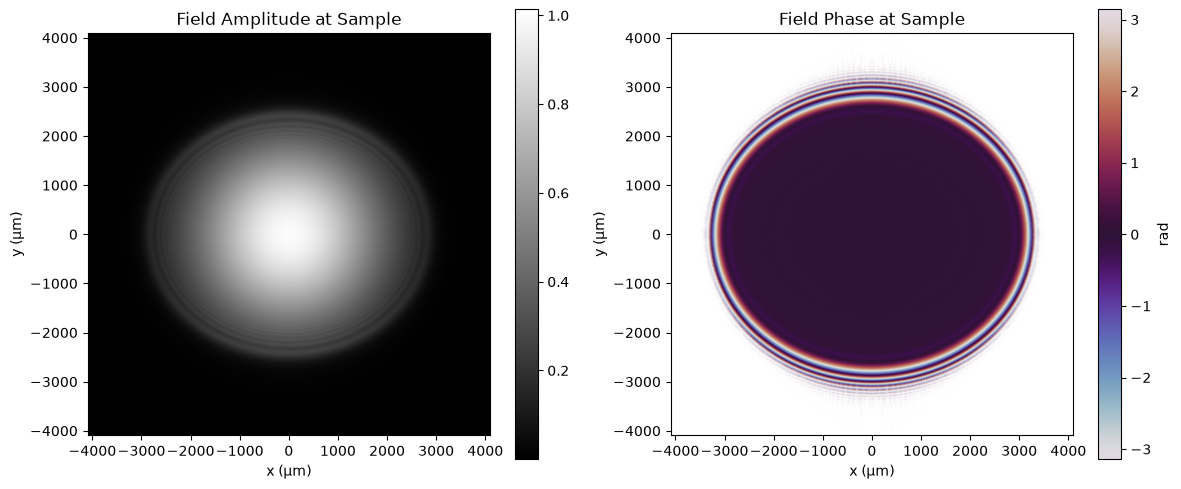

In [9]:
z_sample = 50e3  # distance to sample in micrometers
U_sample = angular_spectrum(U_M1, dx=dx, dy=dy, z=z_sample, lam=central_lam)

plot_field(U_sample, X, Y, 'at Sample', z=z_M1 + z_sample, lam=central_lam)

###Just after sample

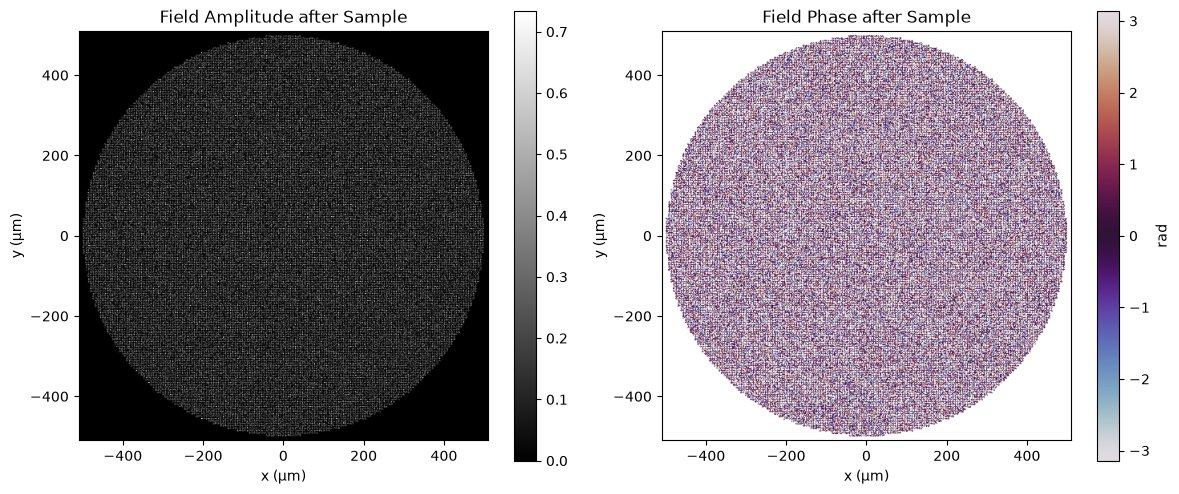

In [10]:
import numpy as np
from doppler_scattering import scattering_vector, mie_amplitude, object_amplitudes, field_after_sample
from utilities import crop

from pathlib import Path

DPD = Path.cwd().parents[1] / "DPD tissue" / "code"

trajs = [dict(np.load(DPD / "runs" / f"cell_{k}" / "traj.npz")) for k in range(4)]
layout = dict(np.load(DPD / "layout.npz"))
q, theta_s = scattering_vector()                    # n = 1.36: |q| ≈ 19.3 µm⁻¹
S_name = {"nucleus": mie_amplitude(1.0, 1.39, 1.36, theta_s),
          "mitochondrion": mie_amplitude(0.44, 1.41, 1.36, theta_s),
          "vesicle": mie_amplitude(0.25, 1.40, 1.36, theta_s)}
amps = object_amplitudes(layout, trajs, S_name)      # once
U_ill, Xc, Yc = crop(U_sample, X, Y, 510)
U_after = field_after_sample(0, U_ill, Xc, Yc, layout, trajs, amps, q)

plot_field(U_after, Xc, Yc, 'after Sample', z=z_M1 + z_sample, lam=central_lam)